# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Đọc `README.md` và `GUIDE.md` trước. Notebook này chỉ là **khung**: bạn tự viết mã theo pseudo code trong GUIDE.

## 0. Môi trường (Colab T4)

In [1]:
# Runtime → Change runtime type → T4 GPU
!nvidia-smi -L
# !pip -q install -r requirements-colab.txt

GPU 0: NVIDIA GeForce RTX 3050 6GB Laptop GPU (UUID: GPU-305e7a5f-8c21-365c-5f9f-fff4dabba51c)


In [2]:
# Kaggle: dùng Colab Secrets trên Colab, hoặc .env khi chạy Local
import os
try:
    from google.colab import userdata
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
except ImportError:
    from dotenv import load_dotenv
    load_dotenv()


## 1. Dữ liệu: tải và chia split

In [ ]:
!python scripts/prepare_data.py --kaggle

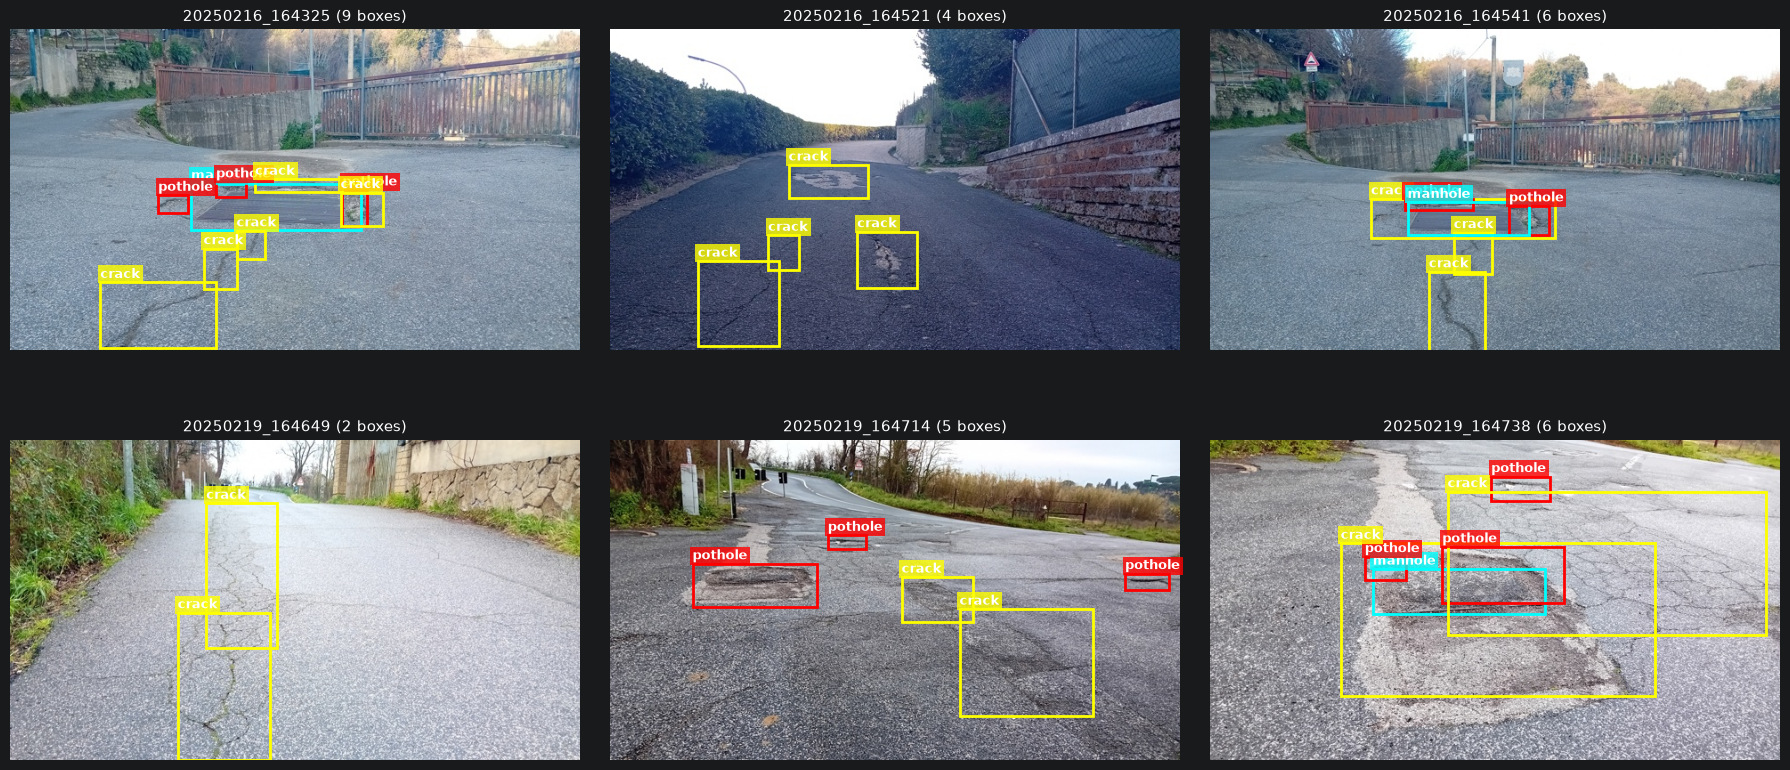

In [4]:
# YOUR CODE HERE: đọc data/splits/train.jsonl, xem vài mẫu, vẽ box lên ảnh
import json
import os
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# 1. Đọc dữ liệu từ file split
with open('data/splits/train.jsonl', 'r', encoding='utf-8') as f:
    train_data = [json.loads(line) for line in f]

# Định nghĩa màu cho từng nhãn
COLOR_MAP = {
    'pothole': 'red',       # Ổ gà
    'crack': 'yellow',      # Vết nứt
    'manhole': 'cyan'       # Nắp cống
}

# 2. Tạo lưới 2 hàng x 3 cột hiển thị 6 ảnh
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.flatten()

for i in range(6):
    sample = train_data[i]
    img_path = os.path.join('data', sample['image_path'])
    img = Image.open(img_path)
    ax = axes[i]
    ax.imshow(img)

    img_w, img_h = sample['width'], sample['height']

    # 3. Vẽ từng box lên ảnh
    for obj in sample['objects']:
        label = obj['label']
        xc, yc, w, h = obj['yolo']

        # Chuyển từ YOLO chuẩn hoá [0, 1] sang pixel tuyệt đối
        x1 = (xc - w / 2) * img_w
        y1 = (yc - h / 2) * img_h
        bw = w * img_w
        bh = h * img_h

        color = COLOR_MAP.get(label, 'lime')
        # Vẽ khung chữ nhật
        rect = patches.Rectangle((x1, y1), bw, bh, linewidth=2, edgecolor=color, facecolor='none')
        ax.add_patch(rect)

        # Ghi tên nhãn lên trên box
        ax.text(x1, max(y1 - 5, 10), label, color='white', fontsize=9, weight='bold',
                bbox=dict(boxstyle='square,pad=0.2', facecolor=color, alpha=0.8, edgecolor='none'))

    ax.set_title(f"{sample['image_id']} ({len(sample['objects'])} boxes)", fontsize=11)
    ax.axis('off')

plt.tight_layout()
plt.show()



## 2. Nhãn: YOLO → JSON thang 0–1000

In [ ]:
# YOUR CODE HERE: viết yolo_to_box() và objects_to_answer() (GUIDE bước 2)


## 3. E0: zero-shot

In [ ]:
# YOUR CODE HERE: nạp model 4-bit, suy luận trên test → work/e0.jsonl (GUIDE bước 3)

In [ ]:
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json

## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [ ]:
# YOUR CODE HERE: encode_example() và collate() (GUIDE bước 4)

## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [ ]:
# YOUR CODE HERE: apply_setup(model, setup) (GUIDE bước 5)

## 6. Vòng huấn luyện

In [ ]:
# YOUR CODE HERE: vòng train, lưu adapter + run.json (GUIDE bước 6)

## 7. Suy luận và chấm E1–E3

In [ ]:
# YOUR CODE HERE: suy luận test → work/eN.jsonl rồi chạy scripts/score.py với --meta (GUIDE bước 7)

## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)

In [ ]:
# YOUR CODE HERE: GUIDE bước 8 và 9